In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from helpers import load_csv_data

DATA_DIR = os.path.expanduser("data/dataset")  # change to your folder
SUB_SAMPLE = False

for f in ("x_train.csv", "y_train.csv", "x_test.csv"):
    path = os.path.join(DATA_DIR, f)
    print(f, "found" if os.path.isfile(path) else "MISSING", "->", path)

x_train.csv found -> /Users/marinollagnon/Library/CloudStorage/ProtonDrive-marin.ollagnon@proton.me-folder/PhD EDBB/Courses/Semester 3/Machine learning/project1/data/dataset/x_train.csv
y_train.csv found -> /Users/marinollagnon/Library/CloudStorage/ProtonDrive-marin.ollagnon@proton.me-folder/PhD EDBB/Courses/Semester 3/Machine learning/project1/data/dataset/y_train.csv
x_test.csv found -> /Users/marinollagnon/Library/CloudStorage/ProtonDrive-marin.ollagnon@proton.me-folder/PhD EDBB/Courses/Semester 3/Machine learning/project1/data/dataset/x_test.csv


In [2]:
# Cache data
cache_file = os.path.join(DATA_DIR, f"cache_sub{int(SUB_SAMPLE)}.npz")
if os.path.exists(cache_file):
    d = np.load(cache_file)
    x_train, x_test, y_train, train_ids, test_ids = (
        d["x_train"], d["x_test"], d["y_train"], d["train_ids"], d["test_ids"])
else:
    x_train, x_test, y_train, train_ids, test_ids = load_csv_data(DATA_DIR, sub_sample=SUB_SAMPLE)
    np.savez(cache_file, x_train=x_train, x_test=x_test, y_train=y_train,
             train_ids=train_ids, test_ids=test_ids)

def read_header(path):
    with open(path) as f:
        return f.readline().strip().split(",")

header_train = read_header(os.path.join(DATA_DIR, "x_train.csv"))[1:]
header_test  = read_header(os.path.join(DATA_DIR, "x_test.csv"))[1:]
y_ids = np.genfromtxt(os.path.join(DATA_DIR, "y_train.csv"), delimiter=",",
                      skip_header=1, dtype=int, usecols=0)
if SUB_SAMPLE:
    y_ids = y_ids[::50]

feature_names = np.array(header_train)

In [3]:
cache_file = os.path.join(DATA_DIR, f"cache_sub{int(SUB_SAMPLE)}.npz")
if os.path.exists(cache_file):
    d = np.load(cache_file)
    x_train, x_test, y_train, train_ids, test_ids = (
        d["x_train"], d["x_test"], d["y_train"], d["train_ids"], d["test_ids"])
else:
    x_train, x_test, y_train, train_ids, test_ids = load_csv_data(DATA_DIR, sub_sample=SUB_SAMPLE)
    np.savez(cache_file, x_train=x_train, x_test=x_test, y_train=y_train,
             train_ids=train_ids, test_ids=test_ids)

def read_header(path):
    with open(path) as f:
        return f.readline().strip().split(",")

header_train = read_header(os.path.join(DATA_DIR, "x_train.csv"))[1:]
header_test  = read_header(os.path.join(DATA_DIR, "x_test.csv"))[1:]
y_ids = np.genfromtxt(os.path.join(DATA_DIR, "y_train.csv"), delimiter=",",
                      skip_header=1, dtype=int, usecols=0)
if SUB_SAMPLE:
    y_ids = y_ids[::50]

feature_names = np.array(header_train)

def col(names, name):
    """Index of a column from its name."""
    return np.where(names == name)[0][0]

In [4]:
#check consistency of train and test data
print("x_train:", x_train.shape)
print("y_train:", y_train.shape)
print("x_test: ", x_test.shape)

checks = {
    "same number of samples in x_train and y_train": x_train.shape[0] == y_train.shape[0],
    "x_train and y_train Ids aligned":               np.array_equal(train_ids, y_ids),
    "same number of features in train and test":     x_train.shape[1] == x_test.shape[1],
    "same feature names and order":                  header_train == header_test,
    "no duplicate Ids":                              len(np.unique(train_ids)) == len(train_ids)
                                                     and len(np.unique(test_ids)) == len(test_ids),
    "no Id in both train and test":                  len(np.intersect1d(train_ids, test_ids)) == 0,
    "labels only -1 / 1":                            set(np.unique(y_train)) <= {-1, 1},
}
for name, ok in checks.items():
    print("OK  " if ok else "FAIL", name)
assert all(checks.values())

y01 = (y_train == 1).astype(int)   # 0/1 labels, only used for descriptive checks and plots
print(f"positives: {y01.mean():.1%}")

x_train: (328135, 321)
y_train: (328135,)
x_test:  (109379, 321)
OK   same number of samples in x_train and y_train
OK   x_train and y_train Ids aligned
OK   same number of features in train and test
OK   same feature names and order
OK   no duplicate Ids
OK   no Id in both train and test
OK   labels only -1 / 1
positives: 8.8%


In [5]:
# remove columns unrelated to health, and leakage
NON_HEALTH = [
    "_STATE", "FMONTH", "IDATE", "IMONTH", "IDAY", "IYEAR", "DISPCODE", "SEQNO", "_PSU",
    "CTELENUM", "PVTRESD1", "COLGHOUS", "STATERES", "CELLFON3", "LADULT", "NUMADULT",
    "NUMMEN", "NUMWOMEN", "CTELNUM1", "CELLFON2", "CADULT", "PVTRESD2", "CCLGHOUS",
    "CSTATE", "LANDLINE", "HHADULT", "NUMHHOL2", "NUMPHON2", "CPDEMO1",
    "QSTVER", "QSTLANG", "MSCODE",
    "_STSTR", "_STRWT", "_RAWRAKE", "_WT2RAKE", "_CHISPNC", "_CLLCPWT",
    "_DUALUSE", "_DUALCOR", "_LLCPWT",
]
LEAKAGE = ["HAREHAB1"]   # cardiac rehab after a heart attack: only filled for positives
print("not found in data:", [c for c in NON_HEALTH + LEAKAGE if c not in header_train])

drop = np.isin(feature_names, NON_HEALTH + LEAKAGE)
x_train_1 = x_train[:, ~drop].copy()
x_test_1  = x_test[:, ~drop].copy()
names_1   = feature_names[~drop]

print(f"removed {drop.sum()} columns")
print("train", x_train_1.shape, " test", x_test_1.shape)


not found in data: []
removed 42 columns
train (328135, 279)  test (109379, 279)


In [6]:
# check which features are follow up to next questions (depend on yes of previous question)
def gate(follow, gate_col, gate_value):
    f = x_train_1[:, col(names_1, follow)]
    g = x_train_1[:, col(names_1, gate_col)]
    present = ~np.isnan(f)
    print(f"{follow:9s} present -> {gate_col}={gate_value}: {np.mean(g[present] == gate_value):.1%}   "
          f"{gate_col}={gate_value} -> {follow} present: {np.mean(present[g == gate_value]):.1%}")

gate("DIABAGE2", "DIABETE3", 1)
gate("BPMEDS",   "BPHIGH4",  1)
gate("SMOKDAY2", "SMOKE100", 1)
gate("JOINPAIN", "HAVARTH3", 1)
gate("INSULIN",  "DIABETE3", 1)

DIABAGE2  present -> DIABETE3=1: 100.0%   DIABETE3=1 -> DIABAGE2 present: 100.0%
BPMEDS    present -> BPHIGH4=1: 100.0%   BPHIGH4=1 -> BPMEDS present: 100.0%
SMOKDAY2  present -> SMOKE100=1: 100.0%   SMOKE100=1 -> SMOKDAY2 present: 99.9%
JOINPAIN  present -> HAVARTH3=1: 100.0%   HAVARTH3=1 -> JOINPAIN present: 90.4%
INSULIN   present -> DIABETE3=1: 100.0%   DIABETE3=1 -> INSULIN present: 51.4%


In [7]:
# fill follow up questions columns with dont know or refused codes, 7 or 9
def fill_follow_ups(x, names):
    x = x.copy()
    # BPMEDS (1 yes / 2 no) is asked only if BPHIGH4 == 1.
    # BPHIGH4 in {2, 3, 4} = no high blood pressure -> not applicable -> 0
    bp, med = col(names, "BPHIGH4"), col(names, "BPMEDS")
    na = np.isnan(x[:, med]) & np.isin(x[:, bp], [2, 3, 4])
    x[na, med] = 0

    # DIABAGE2 (age at diagnosis; 98/99 = don't know/refused) is asked only if DIABETE3 == 1.
    # Replace it by years lived with diabetes, 0 for people without diabetes.
    db, age_dx, age = col(names, "DIABETE3"), col(names, "DIABAGE2"), col(names, "_AGE80")
    a = x[:, age_dx].copy()
    a[a >= 98] = np.nan
    years = np.clip(x[:, age] - a, 0, None)
    years[np.isin(x[:, db], [2, 3, 4])] = 0
    x[:, age_dx] = years
    return x

x_train_1 = fill_follow_ups(x_train_1, names_1)
x_test_1  = fill_follow_ups(x_test_1, names_1)
names_1   = np.where(names_1 == "DIABAGE2", "DIAB_YRS", names_1)

for n in ("BPMEDS", "DIAB_YRS"):
    j = col(names_1, n)
    print(f"{n:9s} missing now: train {np.isnan(x_train_1[:, j]).mean():.1%}, "
          f"test {np.isnan(x_test_1[:, j]).mean():.1%}")

BPMEDS    missing now: train 0.3%, test 0.3%
DIAB_YRS  missing now: train 1.0%, test 1.0%


In [8]:
# set missing rate per column and decide what to remove
MISS_THR = 0.50
GAP_TOL  = 0.05

miss_train = np.mean(np.isnan(x_train_1), axis=0)
miss_test  = np.mean(np.isnan(x_test_1), axis=0)
gap = np.abs(miss_train - miss_test)

remove     = (miss_train > MISS_THR) & (miss_test > MISS_THR) & (gap < GAP_TOL)
to_inspect = ((miss_train > MISS_THR) | (miss_test > MISS_THR)) & ~remove

print(f"largest train/test gap in missing rate: {gap.max():.2%}")
print("to remove:", remove.sum())
print("to inspect by hand:", to_inspect.sum())
for n, a, b in zip(names_1[to_inspect], miss_train[to_inspect], miss_test[to_inspect]):
    print(f"  {n}: train {a:.1%}, test {b:.1%}")

x_train_2 = x_train_1[:, ~remove].copy()
x_test_2  = x_test_1[:, ~remove].copy()
names_2   = names_1[~remove]
print("train", x_train_2.shape, " test", x_test_2.shape)

largest train/test gap in missing rate: 0.21%
to remove: 132
to inspect by hand: 0
train (328135, 147)  test (109379, 147)


In [9]:
# decide what to remove
remove     = (miss_train > MISS_THR) & (miss_test > MISS_THR) & (gap < GAP_TOL)
to_inspect = ((miss_train > MISS_THR) | (miss_test > MISS_THR)) & ~remove

print("to remove:", remove.sum())
print("to inspect by hand:", to_inspect.sum())
for n, a, b in zip(names_1[to_inspect], miss_train[to_inspect], miss_test[to_inspect]):
    print(f"  {n}: train {a:.1%}, test {b:.1%}")

x_train_2 = x_train_1[:, ~remove].copy()
x_test_2  = x_test_1[:, ~remove].copy()
names_2   = names_1[~remove]

print("train", x_train_2.shape, " test", x_test_2.shape)

to remove: 132
to inspect by hand: 0
train (328135, 147)  test (109379, 147)


In [10]:
# remove redundant features
DROP_REDUNDANT = {
    "WTKG3 (kg)":        ["WEIGHT2"],
    "HTM4 (m)":          ["HEIGHT3", "HTIN4"],
    "_CHLDCNT":          ["CHILDREN"],
    "DROCDY3_":          ["ALCDAY5", "DRNKANY5"],
    "_FRUTSUM/_VEGESUM": ["FRUITJU1", "FRUIT1", "FVBEANS", "FVGREEN", "FVORANG", "VEGETAB1",
                          "FTJUDA1_", "FRUTDA1_", "BEANDAY_", "GRENDAY_", "ORNGDAY_", "VEGEDA1_",
                          "_MISFRTN", "_MISVEGN", "_FRTRESP", "_VEGRESP", "_FRTLT1", "_VEGLT1",
                          "_FRT16", "_VEG23", "_FRUITEX", "_VEGETEX"],
    "PA1MIN_/PA1VIGM_/STRFREQ_/_PACAT1/EXERANY2":
                         ["EXEROFT1", "EXERHMM1", "EXRACT11", "EXRACT21", "STRENGTH", "_TOTINDA",
                          "PAMISS1_", "METVL11_", "METVL21_", "ACTIN11_", "ACTIN21_", "PADUR1_",
                          "PAFREQ1_", "_MINAC11", "_MINAC21", "PAMIN11_", "PAMIN21_", "PAVIG11_",
                          "PAVIG21_", "_PAINDX1", "_PA150R2", "_PA300R2", "_PA30021", "_PASTRNG",
                          "_PAREC1", "_PASTAE1"],
    "_AGE80":   ["_AGEG5YR", "_AGE_G", "_AGE65YR", "MAXVO2_", "FC60_"],  # MAXVO2_ = 60-0.55*age (men) / 48-0.37*age (women); FC60_ = 0.6*MAXVO2_/3.5
    "HLTHPLN1": ["_HCVU651"],
    "EDUCA":    ["_EDUCAG"],
    "INCOME2":  ["_INCOMG"],
    "_RACE":    ["_PRACE1", "_MRACE1", "_HISPANC", "_RACEG21", "_RACEGR3", "_RACE_G1"],
    "_BMI5":    ["_BMI5CAT", "_RFBMI5"],
    "GENHLTH":  ["_RFHLTH"],
    "BPHIGH4":  ["_RFHYPE5"],
    "TOLDHI2":  ["_RFCHOL"],
    "BLOODCHO/CHOLCHK": ["_CHOLCHK"],
    "_ASTHMS1": ["ASTHMA3", "_LTASTH1", "_CASTHM1"],
    "HAVARTH3": ["_DRDXAR1"],
    "_SMOKER3": ["SMOKE100", "_RFSMOK3"],
    "_DRNKWEK/_RFBING5": ["_RFDRHV5"],
    "SEATBELT": ["_RFSEAT2", "_RFSEAT3"],
    "HIVTST6":  ["_AIDTST3"],
}
to_drop = [c for cols in DROP_REDUNDANT.values() for c in cols]
print("not found:", [c for c in to_drop if c not in names_2])

keep = ~np.isin(names_2, to_drop)
x_train_3, x_test_3, names_3 = x_train_2[:, keep].copy(), x_test_2[:, keep].copy(), names_2[keep]
print(f"{len(names_2)} -> {len(names_3)} features")

not found: []
147 -> 63 features


In [11]:
def purity(x, names, dropped, kept):
    """Share of rows where `dropped` is fully determined by the `kept` columns (1.0 = nothing lost)."""
    d = x[:, col(names, dropped)]; ok = ~np.isnan(d)
    k = np.column_stack([x[:, col(names, n)] for n in kept])[ok]
    k = np.where(np.isnan(k), -1e9, k)          # treat "missing" as its own value
    _, groups = np.unique(k, axis=0, return_inverse=True)
    groups = groups.ravel(); d = d[ok]
    total = 0
    for g in np.unique(groups):
        _, counts = np.unique(d[groups == g], return_counts=True)
        total += counts.max()                   # rows that agree with the group's most common value
    return total / len(d)

CHECKS = {
    "WEIGHT2": ["WTKG3"], "HEIGHT3": ["HTM4"], "HTIN4": ["HTM4"],
    "_AGEG5YR": ["_AGE80"], "_AGE65YR": ["_AGE80"], "MAXVO2_": ["_AGE80", "SEX"], "FC60_": ["MAXVO2_"],
    "_HCVU651": ["HLTHPLN1", "_AGE80"], "_EDUCAG": ["EDUCA"], "_INCOMG": ["INCOME2"],
    "_PRACE1": ["_RACE"], "_RFHYPE5": ["BPHIGH4"], "_RFCHOL": ["TOLDHI2"], "SMOKE100": ["_SMOKER3"],
    "FRUTDA1_": ["_FRUTSUM"], "_PACAT1": ["PA1MIN_", "PA1VIGM_"], "_RFDRHV5": ["_DRNKWEK", "SEX"],
}
for dropped, kept in CHECKS.items():
    print(f"{dropped:10s} <- {' + '.join(kept):22s} {purity(x_train_2, names_2, dropped, kept):7.2%}")

age, sex, vo = (x_train_2[:, col(names_2, n)] for n in ("_AGE80", "SEX", "MAXVO2_"))
m = (vo < 999) & (age < 80)
print("MAXVO2_ = 60 - 0.55*age (men):  ", np.allclose(vo[m & (sex == 1)], 60 - 0.55 * age[m & (sex == 1)]))
print("MAXVO2_ = 48 - 0.37*age (women):", np.allclose(vo[m & (sex == 2)], 48 - 0.37 * age[m & (sex == 2)]))

WEIGHT2    <- WTKG3                   98.23%
HEIGHT3    <- HTM4                    98.88%
HTIN4      <- HTM4                   100.00%
_AGEG5YR   <- _AGE80                  98.80%
_AGE65YR   <- _AGE80                  98.80%
MAXVO2_    <- _AGE80 + SEX            91.72%
FC60_      <- MAXVO2_                100.00%
_HCVU651   <- HLTHPLN1 + _AGE80       98.96%
_EDUCAG    <- EDUCA                  100.00%
_INCOMG    <- INCOME2                100.00%
_PRACE1    <- _RACE                   95.20%
_RFHYPE5   <- BPHIGH4                100.00%
_RFCHOL    <- TOLDHI2                100.00%
SMOKE100   <- _SMOKER3                99.56%
FRUTDA1_   <- _FRUTSUM                66.47%
_PACAT1    <- PA1MIN_ + PA1VIGM_      87.73%
_RFDRHV5   <- _DRNKWEK + SEX         100.00%
MAXVO2_ = 60 - 0.55*age (men):   True
MAXVO2_ = 48 - 0.37*age (women): True


In [13]:
# columns coded on one digit (decided on train, so train and test get exactly the same rule)
ONE_DIGIT = {n for j, n in enumerate(names_3) if np.nanmax(x_train_3[:, j]) <= 9}

def recode(x, names):
    x = x.copy()
    c = lambda n: col(names, n)

    # follow-up questions: "not asked" means 0
    p = c("POORHLTH")   # asked only if PHYSHLTH or MENTHLTH > 0
    x[np.isnan(x[:, p]) & (x[:, c("PHYSHLTH")] == 88) & (x[:, c("MENTHLTH")] == 88), p] = 0
    no_exercise = x[:, c("EXERANY2")] == 2
    for n in ("PA1MIN_", "PA1VIGM_"):
        x[no_exercise & np.isnan(x[:, c(n)]), c(n)] = 0

    for j, n in enumerate(names):
        v = x[:, j]
        if n in ("PHYSHLTH", "MENTHLTH", "POORHLTH"):      # number of days: 88 = none
            v[v == 88] = 0; v[np.isin(v, [77, 99])] = np.nan
        elif n == "INCOME2":
            v[np.isin(v, [77, 99])] = np.nan
        elif n == "_DRNKWEK":
            v[v == 99900] = np.nan
        elif n == "DROCDY3_":
            v[v == 900] = np.nan
        elif n in ("EMPLOY1", "_RACE", "MARITAL", "EDUCA"):  # here 7 and 8 are real categories
            v[v == 9] = np.nan
        elif n == "CHECKUP1":                                 # 8 = never -> after "5+ years" (4)
            v[np.isin(v, [7, 9])] = np.nan; v[v == 8] = 5
        elif n == "SEATBELT":                                 # 8 = never drives
            v[np.isin(v, [7, 8, 9])] = np.nan
        elif n in ONE_DIGIT:                                  # standard 1-digit questions
            v[np.isin(v, [7, 9])] = np.nan
        x[:, j] = v
    return x

x_train_4 = recode(x_train_3, names_3)
x_test_4  = recode(x_test_3, names_3)

# check: every column should now show only real values
for j, n in enumerate(names_3):
    v = x_train_4[:, j]; u = np.unique(v[~np.isnan(v)])
    shown = u.tolist() if len(u) <= 8 else f"{len(u)} values, {u.min():.2f}..{u.max():.2f}"
    print(f"{n:10s} missing {np.isnan(v).mean():5.1%}  {shown}")

GENHLTH    missing  0.3%  [1.0, 2.0, 3.0, 4.0, 5.0]
PHYSHLTH   missing  2.2%  31 values, 0.00..30.00
MENTHLTH   missing  1.6%  31 values, 0.00..30.00
POORHLTH   missing  1.1%  31 values, 0.00..30.00
HLTHPLN1   missing  0.4%  [1.0, 2.0]
PERSDOC2   missing  0.4%  [1.0, 2.0, 3.0]
MEDCOST    missing  0.3%  [1.0, 2.0]
CHECKUP1   missing  1.4%  [1.0, 2.0, 3.0, 4.0, 5.0]
BPHIGH4    missing  0.3%  [1.0, 2.0, 3.0, 4.0]
BPMEDS     missing  0.3%  [0.0, 1.0, 2.0]
BLOODCHO   missing  2.1%  [1.0, 2.0]
CHOLCHK    missing 14.7%  [1.0, 2.0, 3.0, 4.0]
TOLDHI2    missing 14.1%  [1.0, 2.0]
CVDSTRK3   missing  0.2%  [1.0, 2.0]
CHCSCNCR   missing  0.2%  [1.0, 2.0]
CHCOCNCR   missing  0.2%  [1.0, 2.0]
CHCCOPD1   missing  0.5%  [1.0, 2.0]
HAVARTH3   missing  0.6%  [1.0, 2.0]
ADDEPEV2   missing  0.4%  [1.0, 2.0]
CHCKIDNY   missing  0.3%  [1.0, 2.0]
DIABETE3   missing  0.1%  [1.0, 2.0, 3.0, 4.0]
DIAB_YRS   missing  1.0%  77 values, 0.00..77.00
SEX        missing  0.0%  [1.0, 2.0]
MARITAL    missing  0.7%  [1.0,

In [14]:
# missing values per row: no row is removed, because every test row needs a prediction and test has the same pattern, so train should keep it too
row_miss_train = np.mean(np.isnan(x_train_2), axis=1)
row_miss_test  = np.mean(np.isnan(x_test_2), axis=1)

print("row missing rate, quantiles 50/90/99/max")
print("  train:", np.round(np.quantile(row_miss_train, [.5, .9, .99, 1]), 3))
print("  test: ", np.round(np.quantile(row_miss_test,  [.5, .9, .99, 1]), 3))
for t in (0.1, 0.2, 0.3):
    s = row_miss_train > t
    print(f"> {t:.0%} missing: train {s.sum():6d} rows (pos rate {y01[s].mean():.3f}), "
          f"test {np.sum(row_miss_test > t):6d} rows")

row missing rate, quantiles 50/90/99/max
  train: [0.014 0.156 0.395 0.463]
  test:  [0.014 0.156 0.395 0.456]
> 10% missing: train 110283 rows (pos rate 0.115), test  36762 rows
> 20% missing: train  25435 rows (pos rate 0.080), test   8537 rows
> 30% missing: train  10891 rows (pos rate 0.071), test   3607 rows


In [15]:
# find numerical features and print stats
NOMINAL = ["PERSDOC2", "BPHIGH4", "BPMEDS", "DIABETE3", "MARITAL", "RENTHOM1", "EMPLOY1", "_RACE"]   # categories without order -> one-hot

def n_unique(v):
    return len(np.unique(v[~np.isnan(v)]))

def skew(v):
    v = v[~np.isnan(v)]
    return np.mean((v - v.mean()) ** 3) / v.std() ** 3

numeric = [j for j, n in enumerate(names_3) if n not in NOMINAL and n_unique(x_train_4[:, j]) > 10]
print(f"{len(names_3)} features: {len(numeric)} numeric, {len(names_3) - len(numeric)} categorical / binary / short scales")

print(f"\n{'feature':10s} {'missing':>8s} {'zeros':>6s} {'min':>8s} {'median':>8s} {'mean':>8s} "
      f"{'p99':>8s} {'max':>9s} {'skew':>6s} {'test mean':>10s}")
for j in numeric:
    v, t = x_train_4[:, j], x_test_4[:, j]
    ok = v[~np.isnan(v)]
    print(f"{names_3[j]:10s} {np.isnan(v).mean():8.1%} {np.mean(ok == 0):6.0%} {ok.min():8.2f} "
          f"{np.median(ok):8.2f} {ok.mean():8.2f} {np.quantile(ok, .99):8.2f} {ok.max():9.2f} "
          f"{skew(v):6.1f} {np.nanmean(t):10.2f}")

63 features: 15 numeric, 48 categorical / binary / short scales

feature     missing  zeros      min   median     mean      p99       max   skew  test mean
PHYSHLTH       2.2%    64%     0.00     0.00     4.27    30.00     30.00    2.2       4.24
MENTHLTH       1.6%    69%     0.00     0.00     3.30    30.00     30.00    2.6       3.30
POORHLTH       1.1%    78%     0.00     0.00     2.65    30.00     30.00    3.0       2.64
DIAB_YRS       1.0%    89%     0.00     0.00     1.54    30.00     77.00    4.9       1.56
_AGE80         0.0%     0%    18.00    58.00    55.34    80.00     80.00   -0.4      55.32
HTM4           3.5%     0%     0.91     1.68     1.69     1.93      2.41    0.1       1.69
WTKG3          7.0%     0%    22.68    77.56    80.91   145.15    289.85    1.7      80.95
_BMI5          8.3%     0%    12.02    26.93    28.03    49.43     97.65    2.3      28.04
DROCDY3_       4.9%    50%     0.00     3.00    16.10   100.00    100.00    2.0      16.01
_DRNKWEK       5.8%    50

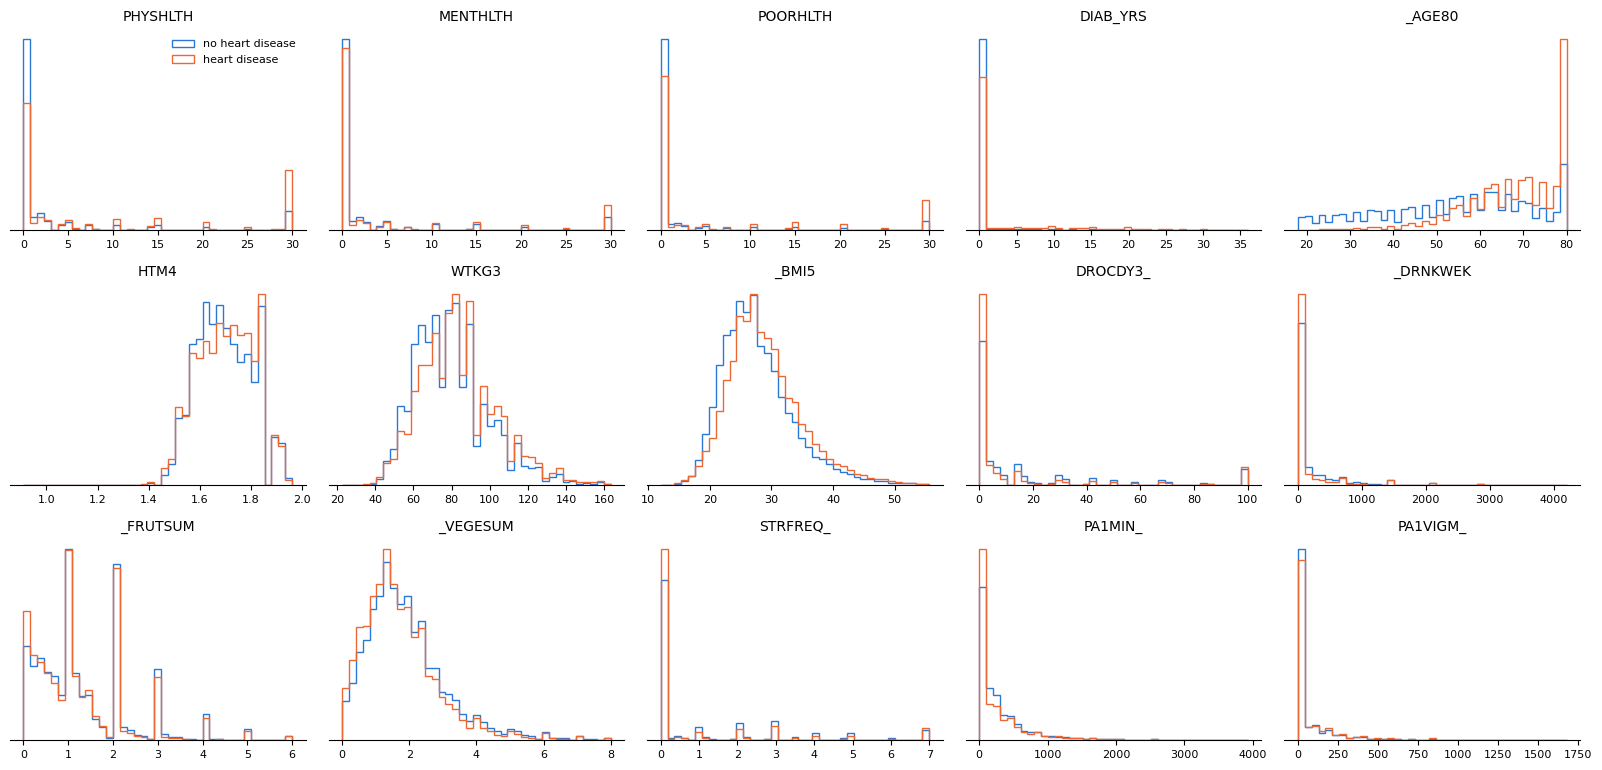

heavily skewed (|skew| > 2): ['PHYSHLTH', 'MENTHLTH', 'POORHLTH', 'DIAB_YRS', '_BMI5', '_DRNKWEK', '_FRUTSUM', '_VEGESUM', 'STRFREQ_', 'PA1MIN_', 'PA1VIGM_']


In [16]:
#plot distributions
NEG, POS = "#2a78d6", "#eb6834"

def plot_distributions(x, names, cols, y01, ncols=5):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 2.6 * nrows))
    for ax, j in zip(axes.ravel(), cols):
        v = x[:, j]; ok = ~np.isnan(v)
        hi = np.quantile(v[ok], 0.995)                       # hide the extreme tail so the shape is visible
        bins = np.linspace(v[ok].min(), hi, 40)
        ax.hist(v[ok & (y01 == 0)], bins=bins, density=True, histtype="step", lw=2, color=NEG, label="no heart disease")
        ax.hist(v[ok & (y01 == 1)], bins=bins, density=True, histtype="step", lw=2, color=POS, label="heart disease")
        ax.set_title(names[j], fontsize=10)
        ax.tick_params(labelsize=8); ax.set_yticks([])
        for s in ("top", "right", "left"):
            ax.spines[s].set_visible(False)
    for ax in axes.ravel()[len(cols):]:
        ax.axis("off")
    axes.ravel()[0].legend(fontsize=8, frameon=False)
    fig.tight_layout()
    plt.show()

plot_distributions(x_train_4, names_3, numeric, y01)

skewed = [names_3[j] for j in numeric if abs(skew(x_train_4[:, j])) > 2]
print("heavily skewed (|skew| > 2):", skewed)

In [17]:
MISS_IND_THR = 0.01   # add a "was missing" column if > 1% missing (set > 1 to disable)

def fit_encoder(x, names):
    enc = []
    for j, n in enumerate(names):
        v = x[:, j]; cats = np.unique(v[~np.isnan(v)])
        if n in NOMINAL:          kind = "onehot"
        elif set(cats) <= {1, 2}: kind = "binary"
        else:                     kind = "numeric"
        enc.append((j, n, kind, cats, np.isnan(v).mean() > MISS_IND_THR))
    return enc

def transform(x, enc):
    cols, names = [], []
    for j, n, kind, cats, add_ind in enc:
        v = x[:, j]; miss = np.isnan(v)
        if kind == "onehot":
            for cat in cats:
                cols.append((v == cat).astype(float)); names.append(f"{n}={cat:g}")
        else:
            if kind == "binary": v = np.where(miss, np.nan, (v == 1).astype(float))
            cols.append(v); names.append(n)
        if add_ind:
            cols.append(miss.astype(float)); names.append(f"{n}_missing")
    return np.column_stack(cols), np.array(names)

def impute_standardize(x_tr, x_te):
    med = np.nanmedian(x_tr, axis=0)
    x_tr = np.where(np.isnan(x_tr), med, x_tr)
    x_te = np.where(np.isnan(x_te), med, x_te)
    mu, sd = x_tr.mean(axis=0), x_tr.std(axis=0); sd[sd == 0] = 1
    return (x_tr - mu) / sd, (x_te - mu) / sd

enc = fit_encoder(x_train_4, names_3)
x_train_5, names_5 = transform(x_train_4, enc)
x_test_5, _        = transform(x_test_4, enc)
x_train_5, x_test_5 = impute_standardize(x_train_5, x_test_5)
print("train", x_train_5.shape, " test", x_test_5.shape)

train (328135, 133)  test (109379, 133)


In [19]:
np.savez(os.path.join(DATA_DIR, "preprocessed.npz"),
         x_train=x_train_5.astype(np.float32), x_test=x_test_5.astype(np.float32), y_train=y_train,
         train_ids=train_ids, test_ids=test_ids, names=names_5)
print("saved preprocessed.npz")

saved preprocessed.npz
